# Data Collection and Single-Stock Exploratory Analysis

## Objective

This notebook introduces the workflow for collecting historical market data and performing a basic exploratory analysis of Reliance Industries (`RELIANCE.NS`).

We inspect the downloaded OHLCV data, visualize adjusted closing prices, calculate daily returns, and estimate historical volatility.

**Data period:** 1 January 2020 to 31 December 2025. The `end` date passed to `yfinance` is exclusive, so the download uses `end="2026-01-01"`.

**Important:** Historical returns and volatility are descriptive statistics, not forecasts of future performance.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

## Libraries

- **pandas** organizes time-indexed market data in DataFrames and Series.
- **NumPy** provides numerical operations.
- **Matplotlib** creates visualizations.
- **yfinance** retrieves historical market data from Yahoo Finance.

We use `auto_adjust=True` so the `Close` series is adjusted for corporate actions such as splits and distributions, making it more suitable for historical return analysis than an unadjusted close series.

In [2]:
reliance = yf.download(
    "RELIANCE.NS",
    start="2020-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)

if reliance.empty:
    raise ValueError("No data was downloaded. Check the ticker, date range, or internet connection.")

# Recent yfinance versions may return MultiIndex columns even for one ticker.
if isinstance(reliance.columns, pd.MultiIndex):
    reliance.columns = reliance.columns.get_level_values(0)

reliance.head()

Price,Close,High,Low,Open,Volume
Date,,,,,
2020-01-01,672.216125,680.008790,670.390471,675.956609,14004468
2020-01-02,683.660217,686.176147,673.284861,673.284861,17710316
2020-01-03,684.484070,686.487896,678.183128,682.636062,20984698
2020-01-06,668.609253,680.364982,667.050708,676.847198,24519177
2020-01-07,678.895569,683.303975,673.952766,676.401873,16683622


## Downloading the Data

The `start` date is inclusive and the `end` date is exclusive. The selected range therefore requests trading data from the start of 2020 through the end of 2025.

## Understanding the OHLCV Data

- **Date:** Trading date (stored as the DataFrame index).
- **Open:** Opening price for the trading session.
- **High:** Highest price reached during the session.
- **Low:** Lowest price reached during the session.
- **Close:** Adjusted closing price because `auto_adjust=True`.
- **Volume:** Number of shares traded, as reported by the data provider.

The market is not open every calendar day, so observations correspond to trading sessions rather than every date.

In [3]:
reliance["Close"].head()

,Close
Date,
2020-01-01,672.216125
2020-01-02,683.660217
2020-01-03,684.484070
2020-01-06,668.609253
2020-01-07,678.895569


The chart below displays the adjusted closing price over time. Price trends alone do not measure investment performance across different assets, but they are useful for initial exploration.

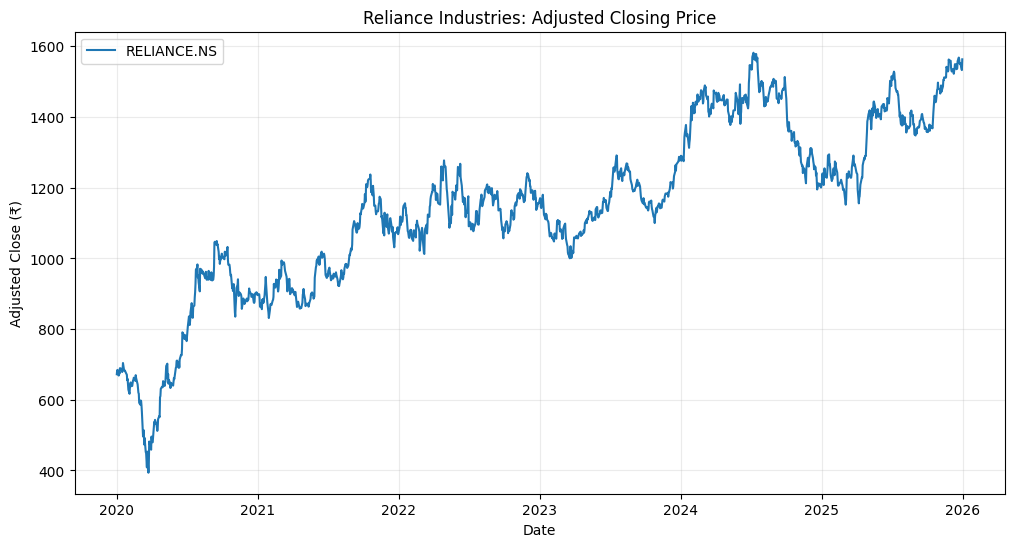

In [4]:
plt.figure(figsize=(12, 6))
plt.plot(reliance.index, reliance["Close"], label="RELIANCE.NS")
plt.title("Reliance Industries: Adjusted Closing Price")
plt.xlabel("Date")
plt.ylabel("Adjusted Close (₹)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

The chart includes a title, axis labels, and a legend to make the figure interpretable. The vertical scale is in rupees.

In [5]:
reliance.describe()

Price,Close,High,Low,Open,Volume
count,1487.000000,1487.000000,1487.000000,1487.000000,1.487000e+03
mean,1142.191475,1153.908898,1131.306581,1142.822463,1.812071e+07
std,239.408407,239.370851,239.157325,239.119059,1.516411e+07
min,393.662354,423.029501,389.921870,407.978540,0.000000e+00
25%,991.279449,1005.344766,981.222709,993.409059,9.577334e+06
50%,1155.959595,1164.704565,1145.758865,1156.058825,1.331159e+07
75%,1311.350220,1317.794535,1295.388033,1313.161153,2.036149e+07
max,1581.824463,1589.630354,1566.607971,1585.332124,1.426834e+08


The next cell summarizes all numeric columns in the downloaded dataset.

In [6]:
reliance["Close"].describe()

,Close
count,1487.000000
mean,1142.191475
std,239.408407
min,393.662354
25%,991.279449
50%,1155.959595
75%,1311.350220
max,1581.824463


The output summarizes the adjusted closing-price distribution. Avoid manually writing numerical conclusions from an old output: the figures can change if the data provider revises historical data or the date range changes.

In [7]:
reliance["Daily Return"] = reliance["Close"].pct_change()
reliance[["Close", "Daily Return"]].head()

Price,Close,Daily Return
Date,,
2020-01-01,672.216125,NaN
2020-01-02,683.660217,0.017024
2020-01-03,684.484070,0.001205
2020-01-06,668.609253,-0.023192
2020-01-07,678.895569,0.015385


## Daily Returns

The percentage change in adjusted closing price from one trading session to the next is

$$
R_t = \frac{P_t-P_{t-1}}{P_{t-1}}.
$$

`pct_change()` returns the decimal return, not a value multiplied by 100. For example, `0.01` represents a 1% return. The first observation is `NaN` because there is no previous price for comparison.

In [8]:
reliance["Daily Return"].dropna().describe()

,Daily Return
count,1486.000000
mean,0.000726
std,0.017810
min,-0.131539
25%,-0.008392
50%,0.000723
75%,0.008513
max,0.147180


The descriptive statistics summarize daily returns in decimal units. Multiply a value by 100 to express it as a percentage. The mean is the average daily return, while the minimum and maximum are the worst and best single-session returns in the sample.

## Volatility

Volatility measures the dispersion of returns and is commonly used as a proxy for investment risk. Here, we use the sample standard deviation of daily returns:

$$
s_R = \sqrt{\frac{1}{N-1}\sum_{t=1}^{N}(R_t-\bar R)^2}.
$$

This is **daily volatility**, not annualized volatility. It describes historical variation and does not guarantee future risk.

The next cell calculates the standard deviation after removing the first missing return.

In [9]:
daily_volatility = reliance["Daily Return"].dropna().std()
print(f"Daily volatility: {daily_volatility:.6f} ({daily_volatility:.2%})")

Daily volatility: 0.017810 (1.78%)


The result is expressed first as a decimal and then as a percentage. For instance, a decimal volatility of `0.018` corresponds to 1.8% daily volatility.

## Visualizing Daily Returns

Returns fluctuate around their average and can show occasional large positive or negative moves. This plot helps reveal variability and outliers that are difficult to see in a price chart.

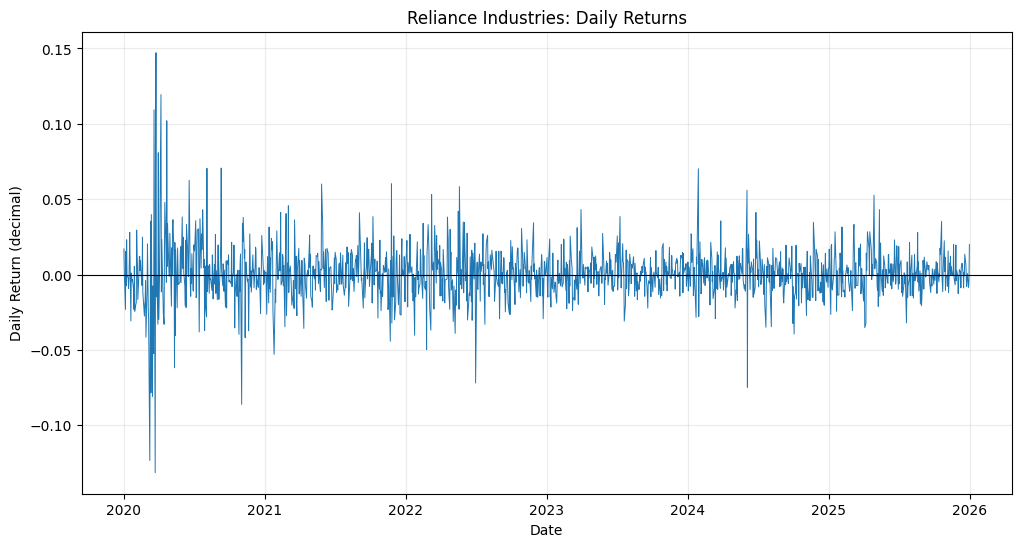

In [10]:
daily_returns = reliance["Daily Return"].dropna()

plt.figure(figsize=(12, 6))
plt.plot(daily_returns.index, daily_returns, linewidth=0.7)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Reliance Industries: Daily Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return (decimal)")
plt.grid(alpha=0.25)
plt.show()